<a href="https://colab.research.google.com/github/Tdhairya2325/UAV-Intelligence-System/blob/main/notebooks/01_data_collection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

# **Environment Setup**

In [24]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

In [25]:

RAW_DIR = "/content/drive/MyDrive/UAV-Intelligence-System/data/raw"

train_matches = glob.glob(
    os.path.join(RAW_DIR, "VisDrone2019-DET-train*")
)

val_matches = glob.glob(
    os.path.join(RAW_DIR, "VisDrone2019-DET-val*")
)

TRAIN_DIR = train_matches[0]
VAL_DIR = val_matches[0]

print("Training path:", TRAIN_DIR)
print("Validation path:", VAL_DIR)

Training path: /content/drive/MyDrive/UAV-Intelligence-System/data/raw/VisDrone2019-DET-train
Validation path: /content/drive/MyDrive/UAV-Intelligence-System/data/raw/VisDrone2019-DET-val


In [28]:
def inspect_dataset(dataset_dir):

    image_dir = os.path.join(dataset_dir, "images")
    annotation_dir = os.path.join(dataset_dir, "annotations")

    images = glob.glob(os.path.join(image_dir, "*.jpg"))
    annotations = glob.glob(os.path.join(annotation_dir, "*.txt"))

    print("\nDataset:", os.path.basename(dataset_dir))
    print("Total images:", len(images))
    print("Total annotations:", len(annotations))
    print("-" * 40)

    return images, annotations


train_images, train_annotations = inspect_dataset(TRAIN_DIR)

val_images, val_annotations = inspect_dataset(VAL_DIR)


Dataset: VisDrone2019-DET-train
Total images: 6471
Total annotations: 6471
----------------------------------------

Dataset: VisDrone2019-DET-val
Total images: 548
Total annotations: 548
----------------------------------------


In [ ]:
print("Training folder exists:", os.path.exists(TRAIN_DIR))
print("Validation folder exists:", os.path.exists(VAL_DIR))

Training folder exists: True
Validation folder exists: True


Image dimensions: (1050, 1400, 3)
Image data type: uint8


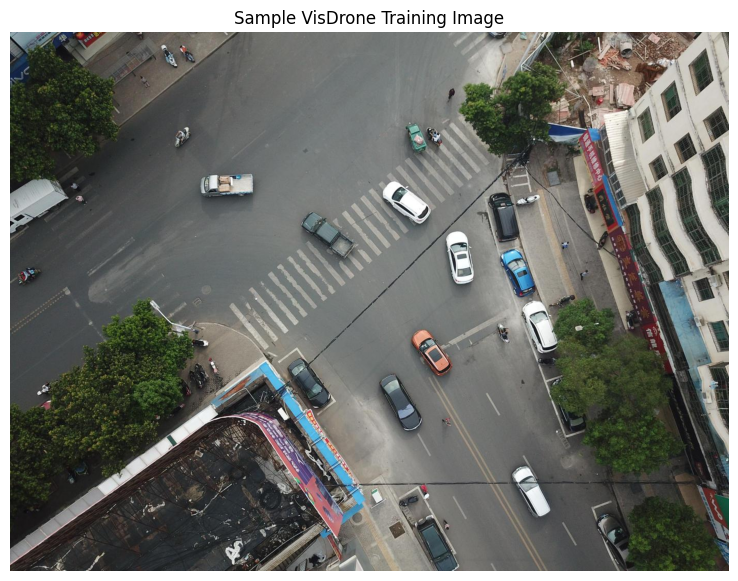

In [29]:


image_path = train_images[0]

image = cv2.imread(image_path)

print("Image dimensions:", image.shape)
print("Image data type:", image.dtype)

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 7))
plt.imshow(image_rgb)
plt.title("Sample VisDrone Training Image")
plt.axis("off")
plt.show()

In [30]:
import pandas as pd

columns = [
    "left",
    "top",
    "width",
    "height",
    "score",
    "category",
    "truncation",
    "occlusion"
]

sample_annotation = train_annotations[0]

df = pd.read_csv(
    sample_annotation,
    header=None,
    names=columns
)

print(df.head())
print("\nTotal objects:", len(df))

   left  top  width  height  score  category  truncation  occlusion
0   842  950     13      19      1         1           0          0
1   805  897     10      13      1         1           0          0
2   953  577     17      18      1         2           0          0
3  1110  460     16      25      1         1           0          0
4  1073  405     15      21      1         1           0          1

Total objects: 52


# **Understand the complete dataset**

In [ ]:
class_names = {
    1: "Pedestrian",
    2: "People",
    3: "Bicycle",
    4: "Car",
    5: "Van",
    6: "Truck",
    7: "Tricycle",
    8: "Awning-tricycle",
    9: "Bus",
    10: "Motor"
}

**Only one Annotation file has 9 columns**

In [31]:
from collections import Counter

column_counts = Counter()

for file in train_annotations:
    try:
        temp = pd.read_csv(file, header=None)
        column_counts[temp.shape[1]] += 1

    except pd.errors.EmptyDataError:
        pass

print("Annotation files grouped by column count:")
print(column_counts)

Annotation files grouped by column count:
Counter({8: 6470, 9: 1})


In [32]:
for file in train_annotations:
    try:
        temp = pd.read_csv(file, header=None)

        if temp.shape[1] != 8:
            print("\nFile:", os.path.basename(file))
            print("Columns:", temp.shape[1])
            print(temp.head())

    except pd.errors.EmptyDataError:
        pass


File: 9999974_00000_d_0000053.txt
Columns: 9
     0    1    2    3  4   5  6  7   8
0  440  541  271  152  1   6  0  0 NaN
1  436  772  134   72  1   5  0  0 NaN
2  601  713   60   39  1  10  0  0 NaN
3  486  706  102   59  1   8  0  0 NaN
4  397  978  167   90  1   4  0  0 NaN


# **All Annotations list**

In [ ]:
all_annotations = []

for file in train_annotations:

    try:
        temp = pd.read_csv(file, header=None)

        # Remove columns that are completely empty
        temp = temp.dropna(axis=1, how="all")

        # Keep only files with the expected 8 columns
        if temp.shape[1] == 8:
            all_annotations.append(temp)
        else:
            print("Unexpected format:", os.path.basename(file))

    except pd.errors.EmptyDataError:
        continue

# Combine all annotation files
annotations_df = pd.concat(all_annotations, ignore_index=True)

# Assign column names
annotations_df.columns = [
    "left", "top", "width", "height",
    "score", "category", "truncation", "occlusion"
]

print("Total annotation rows:", len(annotations_df))
print("\nFirst five rows:")
print(annotations_df.head())

print("\nDataFrame shape:", annotations_df.shape)

Total annotation rows: 353550

First five rows:
   left  top  width  height  score  category  truncation  occlusion
0   842  950     13      19      1         1           0          0
1   805  897     10      13      1         1           0          0
2   953  577     17      18      1         2           0          0
3  1110  460     16      25      1         1           0          0
4  1073  405     15      21      1         1           0          1

DataFrame shape: (353550, 8)


# **Class Distribution**

In [ ]:
valid_objects = annotations_df[
    (annotations_df["score"] == 1) &
    (annotations_df["category"].isin(class_names.keys()))
].copy()

class_distribution = (
    valid_objects["category"]
    .value_counts()
    .reindex(class_names.keys(), fill_value=0)
)

class_distribution.index = class_distribution.index.map(class_names)

print(class_distribution)

category
Pedestrian          79337
People              27059
Bicycle             10480
Car                144867
Van                 24956
Truck               12875
Tricycle             4812
Awning-tricycle      3246
Bus                  5926
Motor               29647
Name: count, dtype: int64


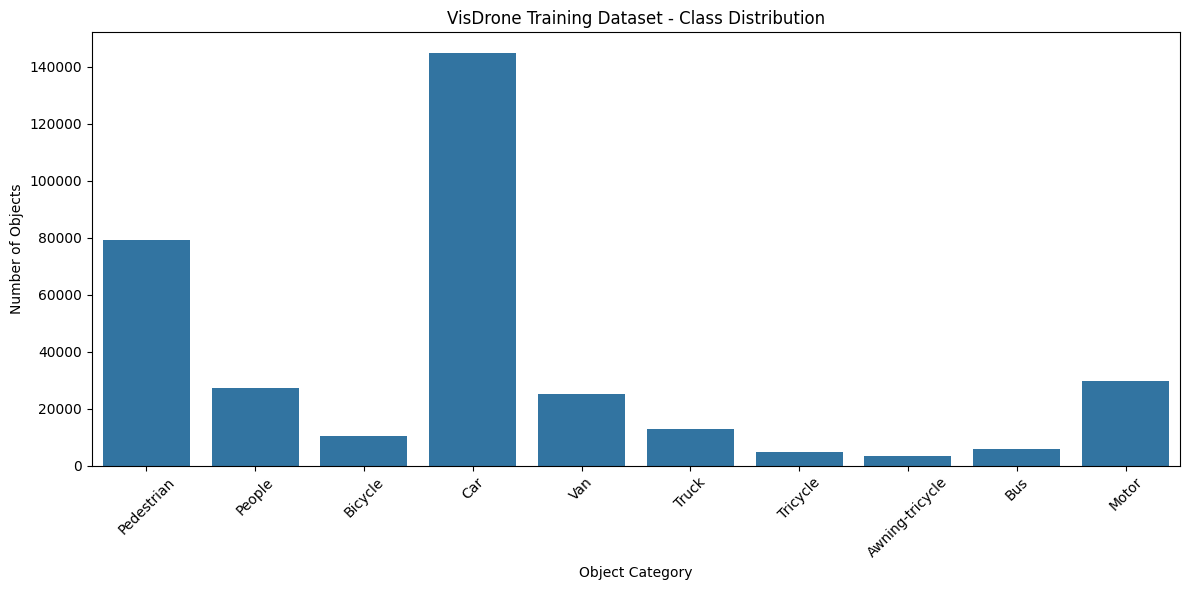

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=class_distribution.index,
    y=class_distribution.values
)

plt.title("VisDrone Training Dataset - Class Distribution")
plt.xlabel("Object Category")
plt.ylabel("Number of Objects")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# **Bounding Box**

In [ ]:
valid_objects["box_area"] = (
    valid_objects["width"] * valid_objects["height"]
)

print(valid_objects["box_area"].describe())

count    343205.000000
mean       2448.398604
std        6598.458460
min           0.000000
25%         243.000000
50%         680.000000
75%        2025.000000
max      328640.000000
Name: box_area, dtype: float64


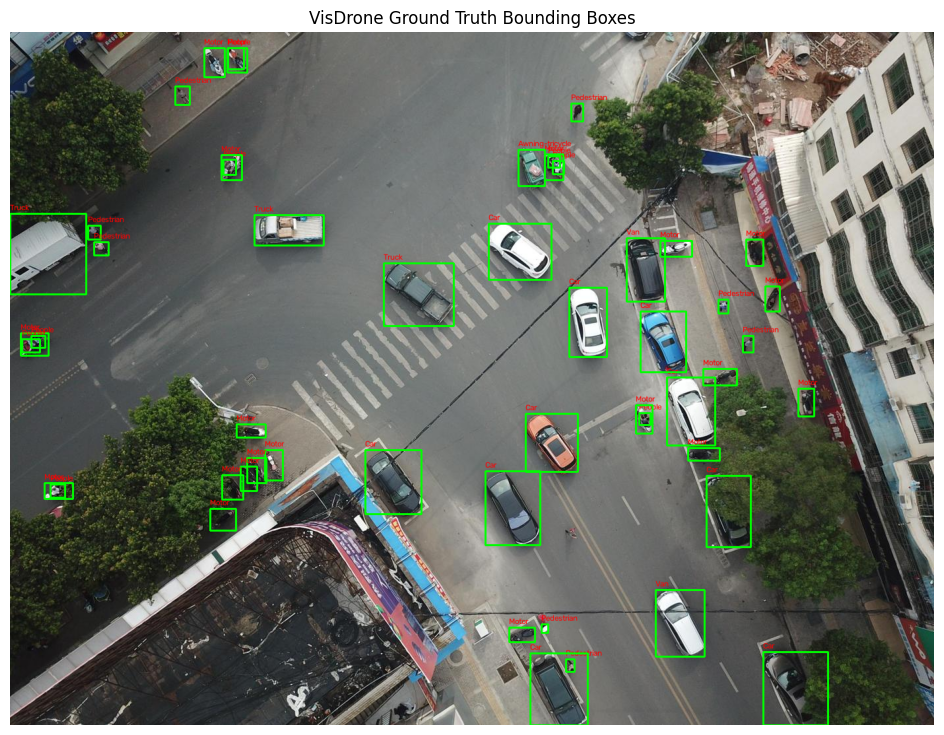

In [ ]:
image_path = train_images[0]

image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

annotation_path = os.path.join(
    TRAIN_DIR,
    "annotations",
    os.path.basename(image_path).replace(".jpg", ".txt")
)

df = pd.read_csv(
    annotation_path,
    header=None,
    names=columns
)

for _, row in df.iterrows():

    category = int(row["category"])

    if category not in class_names:
        continue

    x = int(row["left"])
    y = int(row["top"])
    w = int(row["width"])
    h = int(row["height"])

    label = class_names[category]

    cv2.rectangle(
        image,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

    cv2.putText(
        image,
        label,
        (x, max(y - 5, 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.4,
        (255, 0, 0),
        1
    )

plt.figure(figsize=(14, 9))
plt.imshow(image)
plt.title("VisDrone Ground Truth Bounding Boxes")
plt.axis("off")
plt.show()

# **Check annotation quality**

In [ ]:
print("Missing values in each column:")
print(annotations_df.isnull().sum())


invalid_boxes = annotations_df[
    (annotations_df["width"] <= 0) |
    (annotations_df["height"] <= 0)
]

print("Invalid bounding boxes:", len(invalid_boxes))


print(annotations_df["score"].value_counts())

Missing values in each column:
left          0
top           0
width         0
height        0
score         0
category      0
truncation    0
occlusion     0
dtype: int64
Invalid bounding boxes: 3
score
1    343205
0     10345
Name: count, dtype: int64


# **Out of Bound Boxes**

In [ ]:
from PIL import Image

out_of_bounds = []
missing_images = []
checked_images = 0

# Create a dictionary to match image filenames with paths
image_map = {
    os.path.splitext(os.path.basename(path))[0]: path
    for path in train_images
}

for annotation_path in train_annotations:

    # Extract filename without extension
    filename = os.path.splitext(
        os.path.basename(annotation_path)
    )[0]

    # Find corresponding image
    image_path = image_map.get(filename)

    if image_path is None:
        missing_images.append(filename)
        continue

    # Read image dimensions only
    with Image.open(image_path) as img:
        image_width, image_height = img.size

    # Read annotation file
    try:
        df = pd.read_csv(annotation_path, header=None)

        # Remove completely empty columns
        df = df.dropna(axis=1, how="all")

        if df.shape[1] != 8:
            continue

        df.columns = columns

    except pd.errors.EmptyDataError:
        checked_images += 1
        continue

    # Convert coordinates into numeric values
    coords = df[["left", "top", "width", "height"]].apply(
        pd.to_numeric, errors="coerce"
    )

    # Check bounding boxes outside image boundaries
    mask = (
        (coords["left"] < 0) |
        (coords["top"] < 0) |
        (coords["left"] + coords["width"] > image_width) |
        (coords["top"] + coords["height"] > image_height)
    )

    if mask.any():

        bad_rows = df.loc[mask].copy()
        bad_rows["image"] = filename
        bad_rows["image_width"] = image_width
        bad_rows["image_height"] = image_height

        out_of_bounds.append(bad_rows)

    checked_images += 1

# Combine all problematic annotations
if out_of_bounds:
    out_of_bounds_df = pd.concat(
        out_of_bounds,
        ignore_index=True
    )
else:
    out_of_bounds_df = pd.DataFrame()

print("Images checked:", checked_images)
print("Images without matching annotations:", len(missing_images))
print("Out-of-bounds bounding boxes:", len(out_of_bounds_df))
print(out_of_bounds_df.head())

Images checked: 6471
Images without matching annotations: 0
Out-of-bounds bounding boxes: 0
Empty DataFrame
Columns: []
Index: []


In [ ]:
print("========== DATASET QUALITY REPORT ==========")

print("Total annotation rows:", len(annotations_df))

print("Missing values:",
      annotations_df.isnull().sum().sum())

print("Invalid bounding boxes:",
      len(invalid_boxes))

print("Out-of-bounds boxes:",
      len(out_of_bounds))

print("Valid object annotations:",
      len(valid_objects))

print("============================================")

========== DATASET QUALITY REPORT ==========
Total annotation rows: 353550
Missing values: 0
Invalid bounding boxes: 3
Out-of-bounds boxes: 0
Valid object annotations: 343205


# **Invalid Boxes and their Annotations**

In [ ]:
print(invalid_boxes)

invalid_files = []

for annotation_path in train_annotations:

    try:
        temp = pd.read_csv(annotation_path, header=None)
        temp = temp.dropna(axis=1, how="all")

        if temp.shape[1] != 8:
            continue

        temp.columns = columns

        bad = (
            (temp["width"] <= 0) |
            (temp["height"] <= 0)
        )

        if bad.any():
            print("\nFile:", os.path.basename(annotation_path))
            print(temp[bad])

            invalid_files.append(annotation_path)

    except pd.errors.EmptyDataError:
        continue

print("\nFiles containing invalid boxes:", len(invalid_files))

        left  top  width  height  score  category  truncation  occlusion
52518    545  414     10       0      0         0           0          0
97194    611  158      4       0      1         4           0          0
271255  1008  374      3       0      0         0           0          0

File: 9999999_00590_d_0000267.txt
    left  top  width  height  score  category  truncation  occlusion
88   545  414     10       0      0         0           0          0

File: 9999985_00000_d_0000020.txt
    left  top  width  height  score  category  truncation  occlusion
11   611  158      4       0      1         4           0          0

File: 0000293_03401_d_0000939.txt
     left  top  width  height  score  category  truncation  occlusion
129  1008  374      3       0      0         0           0          0

Files containing invalid boxes: 3


In [ ]:
# Remove annotations with zero or negative width/height
annotations_cleaned = annotations_df[
    (annotations_df["width"] > 0) &
    (annotations_df["height"] > 0)
].copy()

print("Original annotation rows:", len(annotations_df))
print("Cleaned annotation rows:", len(annotations_cleaned))
print("Removed annotation rows:",
      len(annotations_df) - len(annotations_cleaned))

Original annotation rows: 353550
Cleaned annotation rows: 353547
Removed annotation rows: 3


In [ ]:
print("Remaining invalid boxes:")

print(
    len(
        annotations_cleaned[
            (annotations_cleaned["width"] <= 0) |
            (annotations_cleaned["height"] <= 0)
        ]
    )
)

Remaining invalid boxes:
0


# **CLeaned Enotation CSV**

In [33]:


PROJECT_DIR = "/content/drive/MyDrive/UAV-Intelligence-System"

RAW_DIR = os.path.join(PROJECT_DIR, "data", "raw")

PROCESSED_DIR = os.path.join(PROJECT_DIR, "data", "processed")

os.makedirs(PROCESSED_DIR, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Processed directory:", PROCESSED_DIR)

Project directory: /content/drive/MyDrive/UAV-Intelligence-System
Processed directory: /content/drive/MyDrive/UAV-Intelligence-System/data/processed


In [35]:
cleaned_path = os.path.join(
    PROCESSED_DIR,
    "train_annotations_cleaned.csv"
)

annotations_cleaned.to_csv(cleaned_path, index=False)

print("Cleaned annotations saved successfully!")
print("File location:", cleaned_path)

Cleaned annotations saved successfully!
File location: /content/drive/MyDrive/UAV-Intelligence-System/data/processed/train_annotations_cleaned.csv


In [36]:
import os

cleaned_path = os.path.join(
    "/content/drive/MyDrive/UAV-Intelligence-System",
    "data",
    "processed",
    "train_annotations_cleaned.csv"
)

print("File exists:", os.path.exists(cleaned_path))

File exists: True
